# Markowitz Portfolio Optimization
**Dimitar Zhelezov**, Master's in Mathematical Modelling in Economics, FMI, SU

## 1. Introduction

How should an investor split their money between several assets? In 1952, Harry Markowitz answered this question by treating it as a mathematical optimization problem: investors want high expected return and low risk, and these two goals pull against each other. For every target level of return, there is exactly one portfolio with the lowest possible risk. The set of all such portfolios forms the *efficient frontier*, and Markowitz's work became the foundation of modern portfolio theory.

In this project, I shall derive the efficient frontier mathematically and then compute it in Python on real market data (10 assets). I will operate within the scope of the course material (linear algebra, calculus, probability and statistics) and introduce two new concepts: **Lagrange multipliers** (optimization with constraints) and the **matrix inverse**.

The notebook is organized as follows:

1. Introduction and assumptions
2. Setting up the problem
3. Why diversification works
4. The optimization problem
5. New concept: the matrix inverse
6. New concept: Lagrange multipliers
7. The global minimum-variance portfolio
8. The efficient frontier
9. Application to real data
10. Conclusion

### Assumptions
- An investor cares only about the expected return and the risk (variance) of the portfolio.
- There is a single investment period: the investor chooses weights once and holds them.
- Expected returns and covariances are known. In practice they are estimated from historical data.
- There are no transaction costs or taxes, and assets can be bought in any fraction.
- Every asset carries some risk, and no asset's returns are an exact combination of the others' (mathematically: the covariance matrix is invertible).
- Short selling is allowed (weights may be negative).
- A portfolio holds at least 2 assets.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf #I use Yahoo Finance to get my data. The data consists of 10 assets. This library allows #direct access to much financial data

## 2. Setting up the problem

Let $P_{i,t}$ denote the price of asset $i$ at time $t$. The return of asset $i$ over one period is

$$
R_{i,t} = \frac{P_{i,t} - P_{i,t-1}}{P_{i,t-1}}.
$$

Before it is realized, the return is a random variable. An investor splits their wealth across $n$ assets, putting a fraction $w_i$ (the *weight*) into asset $i$, with all weights summing to one:

$$
\sum_{i=1}^{n} w_i = 1 \quad \Longleftrightarrow \quad \mathbf{1}^\top w = 1,
$$

where $\mathbf{1} = (1, \ldots, 1)^\top$ is a vector of ones. Since short selling is allowed, individual weights may be negative or larger than one. This is called the *budget constraint* (it will enter the optimization problem later).

The portfolio return is the weighted sum of the asset returns:

$$
R_p = \sum_{i=1}^{n} w_i R_i = w^\top R,
$$

where $w = (w_1, \ldots, w_n)^\top$ is the vector of weights and $R = (R_1, \ldots, R_n)^\top$ is the random vector of returns (they are random, since they are forward looking).

By linearity of expectation, the expected portfolio return is

$$
\mathbb{E}[R_p] = \mu_p = \sum_{i=1}^{n} w_i \, \mathbb{E}[R_i] = w^\top \mu,
$$

where $\mu = (\mu_1, \ldots, \mu_n)^\top$ is the vector of expected returns.

The risk of a portfolio is measured by the variance of its return. Unlike the expected return, it depends not only on each asset's own variance but also on how the assets move together (their covariances):

$$
\sigma_p^2 = \operatorname{Var}(R_p) = \sum_{i=1}^{n}\sum_{j=1}^{n} w_i w_j \sigma_{ij} = w^\top \Sigma w,
$$

where $\Sigma$ is the covariance matrix of returns, with entries $\sigma_{ij} = \operatorname{Cov}(R_i, R_j)$ and $\sigma_{ii} = \sigma_i^2$. The double sum follows from the bilinearity of covariance: $\operatorname{Var}\left(\sum_i w_i R_i\right) = \sum_i \sum_j w_i w_j \operatorname{Cov}(R_i, R_j)$.

The square root $\sigma_p$ (the standard deviation, or *volatility*) is in the same units as returns, so it is what I plot.

## 3. Why diversification works

### 3.1 Two assets

Take two assets with weights $w$ and $1 - w$. Writing the double sum out by hand,

$$
\sigma_p^2(w) = w^2 \sigma_1^2 + (1-w)^2 \sigma_2^2 + 2w(1-w)\sigma_{12},
$$

where $\sigma_{12} = \rho \, \sigma_1 \sigma_2$ and $\rho$ is the correlation between the two assets. Three cases show what correlation does:

- If $\rho = 1$, then $\sigma_p = w\sigma_1 + (1-w)\sigma_2$: the risk is just the weighted average of the two risks, and mixing the assets brings no benefit.
- If $\rho < 1$, then $\sigma_p$ is *strictly smaller* than that weighted average. This is the benefit of diversification.
- If $\rho = -1$, the two assets move in exactly opposite directions, and some value of $w$ removes all risk.

Because $\sigma_p^2(w)$ is a quadratic polynomial in $w$, we can find the lowest-risk mix with one derivative:

$$
\frac{d\sigma_p^2}{dw} = 2w\sigma_1^2 - 2(1-w)\sigma_2^2 + 2(1-2w)\sigma_{12} = 0
\quad \Longrightarrow \quad
w^* = \frac{\sigma_2^2 - \sigma_{12}}{\sigma_1^2 + \sigma_2^2 - 2\sigma_{12}}.
$$

The second derivative is

$$
\frac{d^2\sigma_p^2}{dw^2} = 2\left(\sigma_1^2 + \sigma_2^2 - 2\sigma_{12}\right) = 2\operatorname{Var}(R_1 - R_2) > 0,
$$

so the function is convex and $w^*$ is a minimum.

**Example:**

Bonds with $\sigma_1 = 5\%$ and stocks with $\sigma_2 = 15\%$, correlation $\rho = 0.2$, so $\sigma_{12} = 0.2 \cdot 0.05 \cdot 0.15 = 0.0015$:

$$
w^* = \frac{0.0225 - 0.0015}{0.0025 + 0.0225 - 2(0.0015)} = \frac{0.021}{0.022} \approx 0.9545,
\qquad \sigma_p \approx 4.95\%.
$$

Adding about 4.5% of an asset that is *three times as risky* makes the portfolio *less* risky than bonds alone.

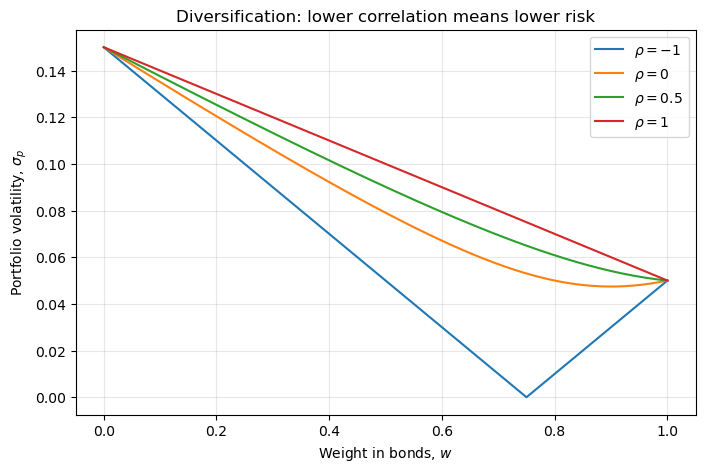

In [ ]:
sigma1 = 0.05
sigma2 = 0.15

#I am going to define the volatility as a function, then plot it, to demonstrate the effects of various correlations (-1, 0, 0.5, 1)
def portfolio_volatility(w, rho):
    cov12 = rho*sigma1*sigma2
    st_dev = np.sqrt(w**2*sigma1**2 + (1 - w)**2*sigma2**2 + 2*w*(1 - w)*cov12)
    return st_dev

#linspace creates an array which gives equal space between each value, resulting in a grid of 201 weights from 0 to 1
w = np.linspace(0, 1, 201)

#I compute and draw one curve per correlation
fig, ax = plt.subplots(figsize=(8, 5))
for rho in [-1, 0, 0.5, 1]:
    ax.plot(w, portfolio_volatility(w, rho), label=rf"$\rho = {rho}$")

ax.set_xlabel(r"Weight in bonds, $w$")
ax.set_ylabel(r"Portfolio volatility, $\sigma_p$")
ax.set_title("Diversification: lower correlation means lower risk")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

### 3.2 Many assets

Now let's take $n$ assets and invest equally in each, so $w_i = \frac{1}{n}$ for every $i$. We start from the general formula for portfolio variance from Section 2:

$$
\sigma_p^2 = \sum_{i=1}^{n}\sum_{j=1}^{n} w_i w_j \sigma_{ij}.
$$

Every product $w_i w_j$ equals $\frac{1}{n} \cdot \frac{1}{n} = \frac{1}{n^2}$, which does not depend on $i$ or $j$, so it moves outside the sums:

$$
\sigma_p^2 = \frac{1}{n^2}\sum_{i=1}^{n}\sum_{j=1}^{n} \sigma_{ij}.
$$

The double sum adds up every entry of the covariance matrix $\Sigma$. Its entries are of two kinds:

- **Diagonal entries** ($i = j$): these are the variances, $\sigma_{ii} = \sigma_i^2$. There are $n$ of them.
- **Off-diagonal entries** ($i \neq j$): these are the covariances between *different* assets. There are $n^2 - n = n(n-1)$ of them, because we subrtact the number of diagonal entries $n$ from the total number of entries $n^2$.

For example, with $n = 3$:

$$
\Sigma = \begin{pmatrix}
\color{blue}{\sigma_1^2} & \sigma_{12} & \sigma_{13} \\
\sigma_{21} & \color{blue}{\sigma_2^2} & \sigma_{23} \\
\sigma_{31} & \sigma_{32} & \color{blue}{\sigma_3^2}
\end{pmatrix},
\qquad \text{3 variances (blue) and } 3 \cdot 2 = 6 \text{ covariances.}
$$

So the double sum can be written as

$$
\sigma_p^2 = \frac{1}{n^2}\sum_{i=1}^{n} \sigma_i^2 + \frac{1}{n^2}\sum_{i \neq j} \sigma_{ij}.
$$

Let

$$
\bar{\sigma}^2 = \frac{1}{n}\sum_{i=1}^{n} \sigma_i^2
\qquad \text{and} \qquad
\bar{c} = \frac{1}{n(n-1)}\sum_{i \neq j} \sigma_{ij}.
$$

$\bar{\sigma}^2$ is the **average variance** of the individual assets (the sum of the $n$ variances, divided by how many there are). $\bar{c}$ is the **average covariance** between two different assets (the sum of the $n(n-1)$ off-diagonal entries, divided by how many there are). Rearranging these definitions gives

$$
\sum_{i=1}^{n} \sigma_i^2 = n\,\bar{\sigma}^2
\qquad \text{and} \qquad
\sum_{i \neq j} \sigma_{ij} = n(n-1)\,\bar{c}.
$$



$$
\begin{aligned}
\sigma_p^2 &= \frac{1}{n^2} \cdot n\,\bar{\sigma}^2 + \frac{1}{n^2} \cdot n(n-1)\,\bar{c} \\
&= \frac{1}{n}\,\bar{\sigma}^2 + \frac{n-1}{n}\,\bar{c}.
\end{aligned}
$$

Assume the average variance and average covariance stay roughly stable as we add assets. As $n \to \infty$:

- $\frac{1}{n} \to 0$, so the first term $\frac{1}{n}\bar{\sigma}^2$ vanishes;
- $\frac{n-1}{n} = 1 - \frac{1}{n} \to 1$, so the second term approaches $\bar{c}$.

Therefore

$$
\sigma_p^2 \;\xrightarrow{\;n \to \infty\;}\; \bar{c}.
$$

The first term is **idiosyncratic risk**: risk specific to individual companies (a failed product, a lawsuit), which averages out across many assets. The second term is **systematic risk**: risk that assets share because they move together (recessions, interest-rate changes). No amount of diversification removes it. A well-diversified portfolio is left with roughly the average covariance of its assets.

**Example.** 

Suppose every asset has volatility $30\%$ (so $\bar{\sigma}^2 = 0.09$) and every pair has correlation $0.3$, so $\bar{c} = 0.3 \cdot 0.3 \cdot 0.3 = 0.027$. A single asset has volatility $30\%$, but a large equal-weight portfolio approaches $\sqrt{0.027} \approx 16.4\%$. Diversification removes almost half the risk, but no more.

## 4. The optimization problem

Markowitz calls a portfolio **efficient** if no other portfolio has a higher expected return with the same risk, or a lower risk with the same expected return. To find all efficient portfolios, we fix a target return $m$ and look for the portfolio with the smallest variance that achieves it:

$$
\min_{w \in \mathbb{R}^n} \; \frac{1}{2} w^\top \Sigma w
\quad \text{subject to} \quad
w^\top \mu = m, \quad \mathbf{1}^\top w = 1.
$$

The factor $\frac{1}{2}$ does not change the solution; it only cancels a 2 when we differentiate. Repeating this for every $m$ traces out the efficient frontier.

In one dimension, a positive second derivative means a function is convex and has at most one minimum. In $n$ dimensions, the role of the second derivative is played by the matrix of second derivatives (also called a Hessian matrix), which here is $\Sigma$. The covariance matrix is *positive definite*:

$$
w^\top \Sigma w = \operatorname{Var}(R_p) > 0 \quad \text{for every } w \neq 0,
$$

which simply says that every portfolio carries some risk (our assumption in Section 1). So the objective is convex, the constraints are linear, and any point where the derivatives vanish is the unique global minimum.

## 5. New concept: the matrix inverse

For numbers, the inverse of $a \neq 0$ is $a^{-1} = 1/a$, because $a^{-1}a = 1$. For a square matrix $A$, the **inverse** $A^{-1}$ is the matrix such that

$$
A^{-1}A = AA^{-1} = I,
$$

where $I$ is the identity matrix (ones on the diagonal, zeros elsewhere). Matrix multiplication is not commutative in general ($AB \neq BA$), but a matrix always commutes with its own inverse: multiplying in either order gives the identity.

A matrix describes a linear transformation. The inverse is the transformation that *undoes* it: applying $A$ and then $A^{-1}$ returns every vector to where it started.

It exists exactly when $\det(A) \neq 0$. The determinant measures how much $A$ scales areas (or volumes). If $\det(A) = 0$, the transformation squashes space into a lower dimension, and the lost information cannot be recovered. For a $2 \times 2$ matrix,

$$
A = \begin{pmatrix} a & b \\ c & d \end{pmatrix},
\qquad
A^{-1} = \frac{1}{ad - bc}\begin{pmatrix} d & -b \\ -c & a \end{pmatrix}.
$$

We need it because it helps us solve systems of linear equations: if $Ax = b$, then $x = A^{-1}b$. Our derivations will produce equations of the form $\Sigma w = v$, so we need $\Sigma^{-1}$ to exist. Suppose it did not, so that $\det(\Sigma) = 0$. Then $\Sigma$ squashes space into a lower dimension, which means some nonzero vector $w$ is sent to zero: $\Sigma w = 0$. But then

$$
\operatorname{Var}(w^\top R) = w^\top \Sigma w = w^\top 0 = 0,
$$

so the combination of assets $w$ would carry no risk at all. This contradicts our assumption in Section 1 that every portfolio carries some risk. Therefore $\det(\Sigma) \neq 0$, and $\Sigma^{-1}$ exists.

In [ ]:
#Let
A = np.array([[1,2,3],[3,16,8],[2,1,5]])
b = np.array([2,5,7])
#We can compare two methods 
inverse = np.linalg.inv(A) #This finds the inverse directly
print(inverse)
#
solved = np.linalg.solve(A,b) #This solves the system directly
print(solved)
#In practice, solve let's us skip a step

[[-5.53846154  0.53846154  2.46153846]
 [-0.07692308  0.07692308 -0.07692308]
 [ 2.23076923 -0.23076923 -0.76923077]]
[ 8.84615385 -0.30769231 -2.07692308]


## 6. New concept: Lagrange multipliers

The course covered unconstrained optimization: at a minimum, the gradient is zero. Our problem has *constraints*, so the weights cannot move freely. Lagrange multipliers extend the "gradient equals zero" rule to this case.

Let us say we minimize $f(x, y)$ while staying on the curve $g(x, y) = c$. At the best point on the curve, moving along the curve cannot decrease $f$. That only happens when the level curve of $f$ just touches the constraint curve, which means their gradients point in the same direction:

$$
\nabla f = \lambda \nabla g
$$

for some number $\lambda$, called the **Lagrange multiplier**.

We build the *Lagrangian* $\mathcal{L}$:

$$
\mathcal{L}(x, y, \lambda) = f(x, y) - \lambda \left( g(x, y) - c \right)
$$

and set *all* its partial derivatives to zero. The derivatives with respect to $x$ and $y$ give $\nabla f = \lambda \nabla g$, and the derivative with respect to $\lambda$ gives back the constraint $g = c$. With several constraints, each gets its own multiplier.

**Example.** 

Let's say we want to minimize $f = x^2 + y^2$ subject to $x + y = 1$:

$$
\mathcal{L} = x^2 + y^2 - \lambda(x + y - 1), \qquad
\frac{\partial \mathcal{L}}{\partial x} = 2x - \lambda = 0, \quad
\frac{\partial \mathcal{L}}{\partial y} = 2y - \lambda = 0.
$$

So $x = y = \lambda/2$, and the constraint gives $x = y = \frac{1}{2}$. Geometrically, this is the point on the line $x + y = 1$ closest to the origin.

The multiplier measures how much the optimal value of $f$ changes if the constraint level $c$ is relaxed slightly.

We will need the gradients of a linear and a quadratic function of $w$. For a vector $a$ and a symmetric matrix $\Sigma$,

$$
\nabla_w \left( a^\top w \right) = a,
\qquad
\nabla_w \left( \tfrac{1}{2} w^\top \Sigma w \right) = \Sigma w.
$$

Both can be checked by writing the sums out and differentiating with respect to one $w_k$ at a time. For example, $\frac{\partial}{\partial w_k}\frac{1}{2}\sum_i\sum_j w_i w_j \sigma_{ij} = \sum_j \sigma_{kj} w_j$, which is the $k$-th entry of $\Sigma w$.

## 7. The global minimum-variance portfolio

First we drop the return target and ask: which portfolio has the lowest possible risk? The only constraint is the budget:

$$
\mathcal{L}(w, \gamma) = \frac{1}{2} w^\top \Sigma w - \gamma \left( \mathbf{1}^\top w - 1 \right),
\qquad
\nabla_w \mathcal{L} = \Sigma w - \gamma \mathbf{1} = 0.
$$

Multiplying by $\Sigma^{-1}$ gives $w = \gamma \, \Sigma^{-1}\mathbf{1}$. The budget constraint $\mathbf{1}^\top w = 1$ then gives $\gamma = 1 / (\mathbf{1}^\top \Sigma^{-1} \mathbf{1})$, so

$$
\boxed{\, w_{\text{GMV}} = \frac{\Sigma^{-1}\mathbf{1}}{\mathbf{1}^\top \Sigma^{-1}\mathbf{1}} \,},
\qquad
\sigma_{\text{GMV}}^2 = \frac{1}{\mathbf{1}^\top \Sigma^{-1}\mathbf{1}}.
$$

For two assets this formula reduces to $w^*$ from Section 3.1. Note that $w_{\text{GMV}}$ uses only $\Sigma$, not the expected returns $\mu$. This matters in practice, because expected returns are much harder to estimate than covariances (Section 10).

In [ ]:
#Let's solve an example with the following values for mu, sigma, and rho (correlation)
mu = np.array([0.04, 0.09, 0.14])
sigma = np.array([0.05, 0.15, 0.25])
corr = np.array([
[1.0, 0.2, 0.1],
[0.2, 1.0, 0.6],
[0.1, 0.6, 1.0],
])

#Covariance matrix: Sigma = D @ R @ D, with D the diagonal matrix of volatilities
D = np.diag(sigma)
Sigma = D @ corr @ D

# GMV weights: w = (Sigma^{-1} @ 1) / (1^T @ Sigma^{-1} @ 1)
ones = np.ones(3)
Sigma_inv = np.linalg.inv(Sigma)
w_gmv = (Sigma_inv @ ones)/(ones @ Sigma_inv @ ones)

print("Weights:", w_gmv)
print("Expected return:", w_gmv @ mu)
print("Volatility:", np.sqrt(w_gmv @ Sigma @ w_gmv))

Weights: [0.95461325 0.03942041 0.00596633]
Expected return: 0.0425676539526955
Volatility: 0.04952899827952504


## 8. The efficient frontier

In Section 7 we found the portfolio with the lowest risk overall. Now we ask a more general question: *for a chosen target return $m$, which portfolio reaches it with the lowest risk?* Answering it for every possible $m$ gives the efficient frontier.

### 8.1 Setting up the Lagrangian

We minimize $\frac{1}{2} w^\top \Sigma w$ subject to two constraints: the portfolio must earn the target return ($w^\top \mu = m$) and the weights must sum to one ($\mathbf{1}^\top w = 1$). Each constraint gets its own Lagrange multiplier, $\lambda$ and $\gamma$:

$$
\mathcal{L}(w, \lambda, \gamma) = \frac{1}{2} w^\top \Sigma w - \lambda \left( w^\top \mu - m \right) - \gamma \left( \mathbf{1}^\top w - 1 \right).
$$

### 8.2 The first-order condition

Using the two derivative rules from Section 6, $\nabla_w \left(\tfrac12 w^\top \Sigma w\right) = \Sigma w$ and $\nabla_w (a^\top w) = a$, the gradient with respect to $w$ is

$$
\nabla_w \mathcal{L} = \Sigma w - \lambda \mu - \gamma \mathbf{1} = 0
\quad \Longrightarrow \quad
\Sigma w = \lambda \mu + \gamma \mathbf{1}.
$$

Multiplying both sides on the left by $\Sigma^{-1}$ (which exists, Section 5) gives the optimal weights:

$$
w^* = \lambda \, \Sigma^{-1}\mu + \gamma \, \Sigma^{-1}\mathbf{1}.
$$

So every optimal portfolio is a combination of just two vectors, $\Sigma^{-1}\mu$ and $\Sigma^{-1}\mathbf{1}$. It remains to find $\lambda$ and $\gamma$.

### 8.3 Four useful numbers

To keep the algebra short, we define four numbers that depend only on the data $\mu$ and $\Sigma$ (following Merton, 1972):

$$
A = \mathbf{1}^\top \Sigma^{-1} \mathbf{1}, \qquad
B = \mathbf{1}^\top \Sigma^{-1} \mu, \qquad
C = \mu^\top \Sigma^{-1} \mu, \qquad
D = AC - B^2.
$$

$A$, $B$ and $C$ are ordinary numbers (a row vector times a matrix times a column vector gives a $1 \times 1$ result). We already met $A$ in Section 7: the minimum variance is $1/A$.

### 8.4 Solving for the multipliers

We substitute $w^*$ into the two constraints. For the return constraint:

$$
\mu^\top w^* = \lambda \, \mu^\top \Sigma^{-1}\mu + \gamma \, \mu^\top \Sigma^{-1}\mathbf{1} = \lambda C + \gamma B = m,
$$

and for the budget constraint:

$$
\mathbf{1}^\top w^* = \lambda \, \mathbf{1}^\top \Sigma^{-1}\mu + \gamma \, \mathbf{1}^\top \Sigma^{-1}\mathbf{1} = \lambda B + \gamma A = 1.
$$

(We used $\mu^\top \Sigma^{-1}\mathbf{1} = \mathbf{1}^\top \Sigma^{-1}\mu = B$, which holds because $\Sigma^{-1}$ is symmetric.) This is a system of two linear equations in $\lambda$ and $\gamma$:

$$
\begin{aligned}
C\lambda + B\gamma &= m, \\
B\lambda + A\gamma &= 1.
\end{aligned}
$$

We solve it by substitution. From the second equation, $\gamma = \dfrac{1 - B\lambda}{A}$. Substituting into the first:

$$
C\lambda + \frac{B(1 - B\lambda)}{A} = m
\;\Longrightarrow\;
\lambda \, \frac{AC - B^2}{A} = m - \frac{B}{A}
\;\Longrightarrow\;
\lambda = \frac{Am - B}{D}.
$$

Substituting $\lambda$ back into $\gamma = (1 - B\lambda)/A$ and simplifying gives

$$
\gamma = \frac{C - Bm}{D}.
$$

### 8.5 Why $D > 0$

We divided by $D$, so we must check that it is not zero. Let $k = B/A$ and consider the vector $\mu - k\mathbf{1}$. Expanding,

$$
(\mu - k\mathbf{1})^\top \Sigma^{-1} (\mu - k\mathbf{1})
= C - 2kB + k^2 A
= C - \frac{B^2}{A}
= \frac{D}{A}.
$$

The left-hand side is positive whenever $\mu - k\mathbf{1} \neq 0$, because $\Sigma^{-1}$ is positive definite like $\Sigma$. (For any $x \neq 0$, set $y = \Sigma^{-1}x$; then $x^\top \Sigma^{-1} x = y^\top \Sigma y > 0$.) Since $A > 0$ as well, we get $D > 0$. The only exception is $\mu = k\mathbf{1}$, meaning all assets have the same expected return. Then there is no trade-off to optimize.

### 8.6 The variance of a frontier portfolio

Now we compute the risk of $w^*$. Using the first-order condition $\Sigma w^* = \lambda\mu + \gamma\mathbf{1}$ and then both constraints:

$$
\sigma^2(m) = w^{*\top} \Sigma w^* = w^{*\top} (\lambda \mu + \gamma \mathbf{1}) = \lambda \, \underbrace{w^{*\top}\mu}_{=\,m} + \gamma \, \underbrace{w^{*\top}\mathbf{1}}_{=\,1} = \lambda m + \gamma.
$$

Substituting $\lambda$ and $\gamma$ from 8.4:

$$
\sigma^2(m) = \frac{(Am - B)\,m}{D} + \frac{C - Bm}{D} = \frac{Am^2 - 2Bm + C}{D}.
$$

This is the key result: the **smallest possible variance** for target return $m$ is a quadratic function of $m$.

### 8.7 The shape: a hyperbola

Completing the square in the numerator:

$$
Am^2 - 2Bm + C = A\left(m - \frac{B}{A}\right)^2 + C - \frac{B^2}{A} = A\left(m - \frac{B}{A}\right)^2 + \frac{D}{A},
$$

so

$$
\sigma^2 = \frac{A}{D}\left(m - \frac{B}{A}\right)^2 + \frac{1}{A}.
$$

Rearranging into standard form:

$$
\frac{\sigma^2}{1/A} - \frac{\left( m - B/A \right)^2}{D/A^2} = 1.
$$

This is the equation of a **hyperbola** in the $(\sigma, m)$ plane, opening to the right.

**Its vertex is the GMV portfolio.** The smallest value of $\sigma^2$ occurs when the squared term is zero, at $m = B/A$, where $\sigma^2 = 1/A$. These are exactly the return and variance of the global minimum-variance portfolio from Section 7, so the two derivations agree.

**Only the upper half is efficient.** For every risk level above the minimum, the hyperbola has two points: one above $m = B/A$ and one below. They have the same risk, but the upper one has the higher return. No rational investor would choose the lower one, so only the upper half ($m \geq B/A$) is the **efficient frontier**.

### 8.8 Two-fund theorem

Since $\lambda$ and $\gamma$ are linear in $m$, so is $w^*$. Collecting the terms with and without $m$:

$$
w^*(m) = g + h\,m, \qquad
g = \frac{C\,\Sigma^{-1}\mathbf{1} - B\,\Sigma^{-1}\mu}{D}, \qquad
h = \frac{A\,\Sigma^{-1}\mu - B\,\Sigma^{-1}\mathbf{1}}{D}.
$$

Take any two frontier portfolios with targets $m_1 \neq m_2$. Any other target can be written as $m = \alpha m_1 + (1-\alpha) m_2$ for some number $\alpha$, and then

$$
w^*(m) = g + h\big(\alpha m_1 + (1-\alpha) m_2\big) = \alpha \, w^*(m_1) + (1 - \alpha) \, w^*(m_2).
$$

So **any two frontier portfolios are enough to build every other one**. In practice, an investor could hold just two well-chosen funds and reach any point on the frontier by changing the mix.

A = 407.64386536373496  B = 17.35244299674267  C = 0.9133811074918567  D = 71.22692725298583


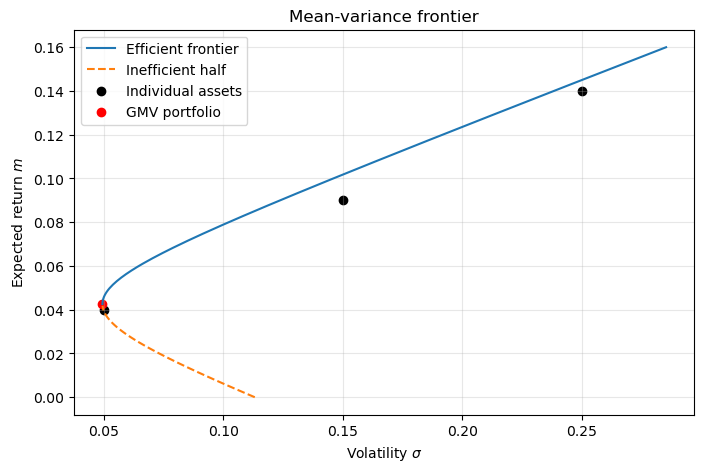

In [ ]:
#Merton's four numbers
A = ones @ Sigma_inv @ ones
B = ones @ Sigma_inv @ mu
C = mu @ Sigma_inv @ mu
D_coef = A * C - B**2
print("A =", A, " B =", B, " C =", C, " D =", D_coef)

#Frontier: sigma(m) = sqrt((A m^2 - 2 B m + C) / D) over a grid of target returns
m = np.linspace(0, 0.16, 200)
sigma_m = np.sqrt((A * m**2 - 2 * B * m + C) / D_coef)
efficient = m >= B / A

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(sigma_m[efficient], m[efficient], label="Efficient frontier")
ax.plot(sigma_m[~efficient], m[~efficient], linestyle="--", label="Inefficient half")
ax.scatter(sigma, mu, color="black", label="Individual assets")
ax.scatter(np.sqrt(1 / A), B / A, color="red", label="GMV portfolio")
ax.set_xlabel(r"Volatility $\sigma$")
ax.set_ylabel(r"Expected return $m$")
ax.set_title("Mean-variance frontier")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## 9. Application to real data

- **Source:** daily prices from Yahoo Finance (`yfinance`), adjusted for dividends and stock splits.
- **Assets (10):** Apple (AAPL), Microsoft (MSFT), JPMorgan Chase (JPM), Johnson & Johnson (JNJ), Procter & Gamble (PG), Coca-Cola (KO), ExxonMobil (XOM), Walmart (WMT), a gold ETF (GLD) and a long-term US Treasury bond ETF (TLT). They cover technology, finance, health care, consumer goods, energy, gold and government bonds, so they are not all strongly correlated.
- **Period:** 2015–2024.
- **Estimates:** the sample mean vector and covariance matrix of daily returns,

$$
\hat{\mu} = \frac{1}{T}\sum_{t=1}^{T} R_t, \qquad
\hat{\Sigma} = \frac{1}{T-1}\sum_{t=1}^{T} (R_t - \hat{\mu})(R_t - \hat{\mu})^\top,
$$

annualized as $\hat{\mu} \times 252$ and $\hat{\Sigma} \times 252$ (about 252 trading days per year).

[*********************100%***********************]  10 of 10 completed


Number of trading days: 2515
        Annual return  Annual volatility
Ticker                                  
AAPL            0.274              0.285
GLD             0.085              0.141
JNJ             0.077              0.181
JPM             0.199              0.274
KO              0.087              0.178
MSFT            0.272              0.271
PG              0.107              0.185
TLT            -0.001              0.153
WMT             0.158              0.211
XOM             0.097              0.278


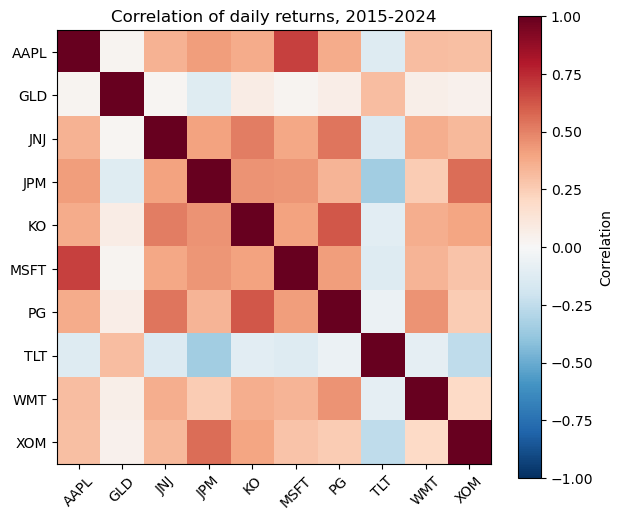

In [ ]:
tickers = ["AAPL", "MSFT", "JPM", "JNJ", "PG", "KO", "XOM", "WMT", "GLD", "TLT"]
prices = yf.download(tickers, start="2015-01-01", end="2025-01-01", auto_adjust=True)["Close"]
prices = prices.dropna()
returns = prices.pct_change().dropna()

#Annualized estimates
mu_hat = returns.mean() * 252
Sigma_hat = returns.cov() * 252
names = mu_hat.index #yfinance sorts the tickers alphabetically

print("Number of trading days:", len(returns))
print(pd.DataFrame({"Annual return": mu_hat, "Annual volatility": np.sqrt(np.diag(Sigma_hat))}).round(3))

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(returns.corr(), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(names)), names, rotation=45)
ax.set_yticks(range(len(names)), names)
fig.colorbar(im, ax=ax, label="Correlation")
ax.set_title("Correlation of daily returns, 2015-2024")
plt.show()

GMV weights:
Ticker
AAPL    0.007
GLD     0.251
JNJ     0.113
JPM     0.098
KO      0.048
MSFT   -0.007
PG      0.031
TLT     0.352
WMT     0.075
XOM     0.032
dtype: float64
GMV expected return: 0.07179559065112473  volatility: 0.08552110186626026


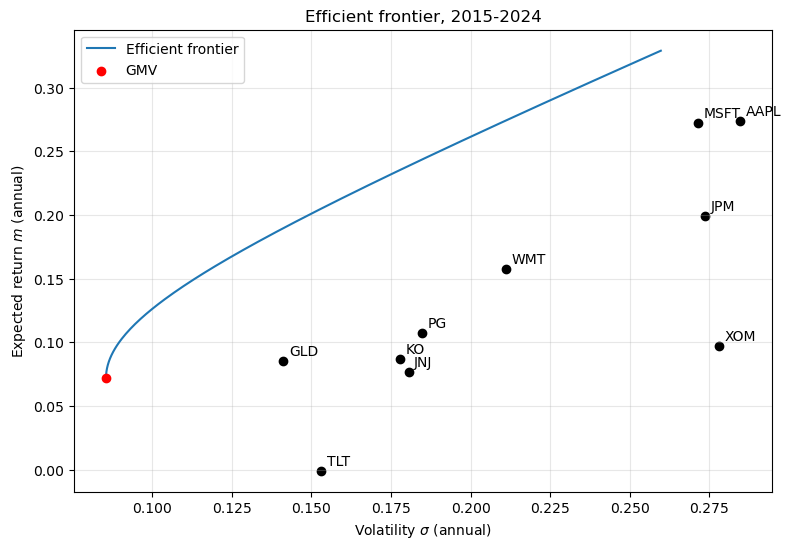

In [ ]:
mu_v = mu_hat.values
S = Sigma_hat.values
S_inv = np.linalg.inv(S)
one = np.ones(len(mu_v))

#GMV portfolio (Section 7)
w_gmv_hat = (S_inv @ one) / (one @ S_inv @ one)

#Frontier (Section 8)
A_hat = one @ S_inv @ one
B_hat = one @ S_inv @ mu_v
C_hat = mu_v @ S_inv @ mu_v
D_hat = A_hat * C_hat - B_hat**2
m_grid = np.linspace(B_hat / A_hat, 1.2 * mu_v.max(), 200)
sigma_grid = np.sqrt((A_hat * m_grid**2 - 2 * B_hat * m_grid + C_hat) / D_hat)

print("GMV weights:")
print(pd.Series(w_gmv_hat, index=names).round(3))
print("GMV expected return:", w_gmv_hat @ mu_v, " volatility:", np.sqrt(w_gmv_hat @ S @ w_gmv_hat))

fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(sigma_grid, m_grid, label="Efficient frontier")
ax.scatter(np.sqrt(np.diag(S)), mu_v, color="black")
for name, x, y in zip(names, np.sqrt(np.diag(S)), mu_v):
    ax.annotate(name, (x, y), xytext=(4, 4), textcoords="offset points")
ax.scatter(np.sqrt(w_gmv_hat @ S @ w_gmv_hat), w_gmv_hat @ mu_v, color="red", zorder=3, label="GMV")
ax.set_xlabel(r"Volatility $\sigma$ (annual)")
ax.set_ylabel(r"Expected return $m$ (annual)")
ax.set_title("Efficient frontier, 2015-2024")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## 10. Conclusion

On the 10 assets, the minimum-variance portfolio is dominated by the long-term Treasury bond ETF (TLT, 35.2%) and gold (GLD, 25.1%), followed by Johnson & Johnson (11.3%) and JPMorgan (9.8%). It has an annual volatility of 8.55%, well below that of the least risky single asset (gold, 14.1%), with an expected return of 7.18%. Notably, TLT receives the largest weight even though its estimated return over 2015–2024 was slightly negative (−0.1%). The minimum-variance portfolio ignores expected returns entirely and chooses assets only for how they reduce risk, here through their low correlation with stocks. The one negative weight, a small short position in Microsoft (−0.7%), shows that the unconstrained solution can short assets.

**Limitations.**

- **Estimation error.** The theory assumes $\mu$ and $\Sigma$ are known, but we only have estimates from past data, and expected returns are especially hard to estimate. The optimized weights are very sensitive to them. Common remedies are shrinking the covariance matrix (Ledoit and Wolf, 2004) or combining market equilibrium with investor views (Black and Litterman, 1992).
- **Short selling.** We allowed negative weights. Requiring $w \geq 0$ removes the closed-form solution, and the problem must be solved numerically.
- **Variance treats gains and losses alike**, and real returns have fatter tails than the normal distribution.
- **Single period.** The model ignores rebalancing over time and transaction costs.

## References

1. Markowitz, H. (1952). Portfolio Selection. *The Journal of Finance*, 7(1), 77–91.
2. Merton, R. C. (1972). An Analytic Derivation of the Efficient Portfolio Frontier. *Journal of Financial and Quantitative Analysis*, 7(4), 1851–1872.
3. Black, F., & Litterman, R. (1992). Global Portfolio Optimization. *Financial Analysts Journal*, 48(5), 28–43.
4. Ledoit, O., & Wolf, M. (2004). Honey, I Shrunk the Sample Covariance Matrix. *The Journal of Portfolio Management*, 30(4), 110–119.
5. Course materials: High-School Maths, Linear Algebra, Calculus, Probability and Combinatorics, Statistics.

In [ ]:
#Thank you for sticking to the end :)